[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/phildani7/why-book-of-deep-learning-part-1/blob/main/notebooks/ch17_LabCh17_Residual_Blocks_And_Transfer_Learning.ipynb)

**The Why Book of Deep Learning, Part 1** by Dr. Philemon Paul Daniel

**Chapter 17: Famous Architectures and the Skip Connection** (Part III: Seeing).

* Read this chapter free online: [www.micyaai.com/books/why-deep-learning-1/read.html?ch=17](https://www.micyaai.com/books/why-deep-learning-1/read.html?ch=17)
* The simplified video course for kids that this book grew from: [aikids.guru](https://www.aikids.guru)
* All the notebooks for the book: [github.com/phildani7/why-book-of-deep-learning-part-1](https://github.com/phildani7/why-book-of-deep-learning-part-1)

Tested with TensorFlow 2.21 and Keras 3.14. In Colab: *Runtime > Run all*. A GPU runtime makes the bigger
models faster but none of them needs one.

---


# Lab Ch17 - Residual Blocks and Transfer Learning
## Build the skip connection by hand, watch it rescue a deep network, then borrow a pretrained one

This lab goes with **Chapter 17** of *The Why Book of Deep Learning*.

A residual block is two convolutions and one addition. That addition costs **zero parameters**, and it is
the reason networks went from about 20 trainable layers to more than 150. In Part A you build plain and
residual blocks with the Functional API, count every parameter by hand, break a block on purpose with a
shape mismatch and repair it with a 1 x 1 projection, and then train two 20-layer networks that differ
only in their skips. In Part B you take a ready-made backbone from `keras.applications`, freeze it, put a
new head on it and run the two-phase transfer-learning recipe.

### What you will be able to do afterwards

| Skill | Where |
|---|---|
| Build a plain block and a residual block with the Functional API | Steps 2 and 3 |
| Explain why a residual block can start life as "do nothing" | Step 4 |
| Read the error when the skip and the main path disagree, and fix it with a 1 x 1 projection | Steps 5 and 6 |
| Count a bottleneck block by hand | Step 7 |
| Measure the gradient that reaches the first layer, with and without skips | Step 10 |
| Compare a plain and a residual network of the same depth | Steps 11 and 12 |
| Freeze a backbone and read trainable / non-trainable counts | Steps 13 to 15 |
| Run feature extraction, then fine-tuning with a small learning rate | Steps 16 and 17 |

### The rule of this lab: predict, then run

Every step asks you to **write down a prediction before you run the cell**. Being wrong on paper is how
the idea sticks.

> **Runtime:** a laptop CPU is enough: about four minutes plus the time to import TensorFlow.
> To stay that fast, Part A trains on **10,000** CIFAR-10 images for **6 epochs**, and Part B uses
> **2,000** images and a very small backbone. For a real run, use all 50,000 images and 30 or more epochs.
> Your exact numbers will differ a little from the ones quoted in the text (different CPUs add numbers in
> different orders), but the comparisons keep the same direction.

---
# Part A - The residual block

---
## Step 1 - Imports and one seed

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(42)
np.set_printoptions(precision=4, suppress=True)

print("TensorFlow:", tf.__version__)
print("Keras     :", keras.__version__)

TensorFlow: 2.21.0
Keras     : 3.14.1


---
## Step 2 - A plain block

Two 3 x 3 convolutions with `padding='same'`, the pattern of the CIFAR-10 network in Chapter 16.
We feed it a feature map of shape `(32, 32, 32)`: 32 x 32 pixels, 32 channels.

The parameter rule from Chapter 14: each filter has `3 x 3 x channels_in` weights and one bias.

> **Predict:** the output shape, and the parameter count of each convolution and of the whole block.

In [2]:
def plain_block(x, filters):
    y = layers.Conv2D(filters, 3, padding='same', activation='relu')(x)
    y = layers.Conv2D(filters, 3, padding='same')(y)
    return layers.ReLU()(y)

inp = keras.Input(shape=(32, 32, 32))
plain = keras.Model(inp, plain_block(inp, 32), name='plain_block')
plain.summary()

hand = 2 * ((3 * 3 * 32 + 1) * 32)
print("hand count:", hand)
assert plain.count_params() == hand == 18_496

Model: "plain_block"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 32, 32, 32)     │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,496 (72.25 KB)

 Trainable params: 18,496 (72.25 KB)

 Non-trainable params: 0 (0.00 B)

hand count: 18496


---
## Step 3 - A residual block

The same two convolutions, plus one line: **add the block's input to its output** before the last ReLU.
The main path no longer has to produce the answer. It only has to produce the *correction* to its input.

```
         x ───────────────────────────┐   (the skip: identity)
         │                            │
         └─> Conv 3x3 ─> ReLU ─> Conv 3x3 ─> (+) ─> ReLU ─> out
```

> **Predict:** how many parameters does the `Add` layer have? So what is the block's total?

In [3]:
def residual_block(x, filters):
    shortcut = x
    y = layers.Conv2D(filters, 3, padding='same', activation='relu')(x)
    y = layers.Conv2D(filters, 3, padding='same')(y)
    y = layers.Add()([shortcut, y])      # the skip connection
    return layers.ReLU()(y)

inp = keras.Input(shape=(32, 32, 32))
res = keras.Model(inp, residual_block(inp, 32), name='residual_block')
res.summary()

print("plain block   :", plain.count_params())
print("residual block:", res.count_params())
assert res.count_params() == plain.count_params()

Model: "residual_block"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 32, 32,    │          0 │ -                 │
│ (InputLayer)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 32, 32,    │      9,248 │ input_layer_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 32, 32,    │      9,248 │ conv2d_2[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 32, 32,    │          0 │ input_layer_1[0]… │
│                     │ 32)               │            │ conv2d_3[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_1 (ReLU)      │ (None, 32, 32,    │          0 │ add[0][0]         │
│                     │ 32)               │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 18,496 (72.25 KB)

 Trainable params: 18,496 (72.25 KB)

 Non-trainable params: 0 (0.00 B)

plain block   : 18496
residual block: 18496


### Why we see this

Exactly the same count, 18,496. `Add` has nothing to learn: it adds two tensors element by element.
The skip connection is **free** in parameters and almost free in arithmetic (one addition per number,
against 288 multiply-adds per number in each convolution). Whatever the skip buys, it buys it without
making the model bigger. Notice also that the summary of the residual model is no longer a straight list:
the `Add` row names *two* inputs. That is why a skip needs the Functional API.

---
## Step 4 - The block that can do nothing

Here is the central idea of ResNet. Suppose training decides that this block is not needed. What must
the weights become?

- For the **plain** block to pass its input through unchanged, its two convolutions must learn to be an
  exact identity map: a precise pattern of weights, hard to find by gradient descent.
- For the **residual** block, it is enough that the second convolution outputs zero. Zero is easy:
  weight decay alone pushes weights towards it.

We set the last convolution of each block to all zeros and feed in a random non-negative input
(as if it came out of a ReLU).

> **Predict:** what does each block output?

In [4]:
def zero_last_conv(model):
    conv = [l for l in model.layers if isinstance(l, layers.Conv2D)][-1]
    conv.set_weights([np.zeros_like(w) for w in conv.get_weights()])

zero_last_conv(plain)
zero_last_conv(res)

x_test_block = np.random.rand(1, 32, 32, 32).astype('float32')   # values in [0, 1)
out_plain = plain(x_test_block).numpy()
out_res = res(x_test_block).numpy()

print("plain block output: max |value| =", np.abs(out_plain).max())
print("residual output   : max |out - x| =", np.abs(out_res - x_test_block).max())

plain block output: max |value| = 0.0
residual output   : max |out - x| = 0.0


### Why we see this

The plain block with a silent last layer destroys its input: everything is zero. The residual block with
a silent last layer is a perfect copy machine: output equals input. In a residual network,
**"leave the signal alone" is the default**, and every block only has to learn how to improve on it.
Stack 50 blocks that each start near identity and the whole network starts near identity, so the signal
(and, on the way back, the gradient) reaches every layer.

---
## Step 5 - Break it on purpose: the skip and the main path disagree

`Add` needs two tensors of **identical shape**. Now let the block change the number of channels from
32 to 64 and halve the picture with `strides=2`, as every network does when it moves to the next stage.

> **Predict:** the shape of the main path, the shape of the skip, and what Keras says.

In [5]:
def residual_block_naive(x, filters, stride):
    shortcut = x
    y = layers.Conv2D(filters, 3, strides=stride, padding='same', activation='relu')(x)
    y = layers.Conv2D(filters, 3, padding='same')(y)
    print("main path:", y.shape, "   skip:", shortcut.shape)
    y = layers.Add()([shortcut, y])
    return layers.ReLU()(y)

inp = keras.Input(shape=(32, 32, 32))
try:
    residual_block_naive(inp, 64, stride=2)
except ValueError as err:
    print("\nValueError:", str(err).strip().split("\n")[0][:300])

main path: (None, 16, 16, 64)    skip: (None, 32, 32, 32)

ValueError: Inputs have incompatible shapes. Received shapes (32, 32, 32) and (16, 16, 64)


---
## Step 6 - The fix: a 1 x 1 projection on the skip

When the shapes differ, the skip gets its own tiny layer: a **1 x 1 convolution** with the new number of
filters and the same stride. It reshapes the skip, (32, 32, 32) into (16, 16, 64), without looking at
neighbours. Its cost is `(channels_in + 1) x filters`.

The ResNet paper calls this a *projection shortcut*. When shapes already match, the skip stays a plain
identity, which is free.

> **Predict:** the projection's parameter count, and the block's total.
> (The two 3 x 3 convolutions: (3x3x32 + 1) x 64 and (3x3x64 + 1) x 64.)

In [6]:
def residual_block_v2(x, filters, stride=1):
    shortcut = x
    y = layers.Conv2D(filters, 3, strides=stride, padding='same', activation='relu')(x)
    y = layers.Conv2D(filters, 3, padding='same')(y)
    if stride != 1 or x.shape[-1] != filters:                  # shapes differ?
        shortcut = layers.Conv2D(filters, 1, strides=stride)(x)   # 1 x 1 projection
    y = layers.Add()([shortcut, y])
    return layers.ReLU()(y)

inp = keras.Input(shape=(32, 32, 32))
down = keras.Model(inp, residual_block_v2(inp, 64, stride=2), name='downsampling_block')
print("output shape:", down.output.shape)

c1 = (3 * 3 * 32 + 1) * 64
c2 = (3 * 3 * 64 + 1) * 64
proj = (32 + 1) * 64
print(f"conv1 {c1:,} + conv2 {c2:,} + projection {proj:,} = {c1 + c2 + proj:,}")
assert down.count_params() == c1 + c2 + proj == 57_536

output shape: (None, 16, 16, 64)
conv1 18,496 + conv2 36,928 + projection 2,112 = 57,536


---
## Step 7 - Count a bottleneck block

Deep ResNets (50 layers and more) use a cheaper block on wide feature maps: a 1 x 1 convolution squeezes
256 channels down to 64, a 3 x 3 convolution works on the thin version, and another 1 x 1 restores 256.
Compare it with two ordinary 3 x 3 convolutions at the full 256 channels.

(Real ResNets put BatchNormalization after each convolution and drop the biases; we keep the biases
here so the arithmetic matches Chapter 14's rule exactly.)

> **Predict:** roughly how many times cheaper is the bottleneck?

In [7]:
def bottleneck_block(x, squeeze=64, width=256):
    y = layers.Conv2D(squeeze, 1, activation='relu')(x)               # 256 -> 64
    y = layers.Conv2D(squeeze, 3, padding='same', activation='relu')(y) # 64 -> 64
    y = layers.Conv2D(width, 1)(y)                                     # 64 -> 256
    return layers.ReLU()(layers.Add()([x, y]))

inp = keras.Input(shape=(14, 14, 256))
bott = keras.Model(inp, bottleneck_block(inp))
wide = keras.Model(inp, residual_block(inp, 256))

b_hand = (256 + 1) * 64 + (3 * 3 * 64 + 1) * 64 + (64 + 1) * 256
w_hand = 2 * (3 * 3 * 256 + 1) * 256
print(f"bottleneck block : {bott.count_params():,}   (hand {b_hand:,})")
print(f"two 3x3 at 256   : {wide.count_params():,}   (hand {w_hand:,})")
print(f"ratio            : {w_hand / b_hand:.1f} x")
assert bott.count_params() == b_hand and wide.count_params() == w_hand

bottleneck block : 70,016   (hand 70,016)
two 3x3 at 256   : 1,180,160   (hand 1,180,160)
ratio            : 16.9 x


---
## Step 8 - A small slice of CIFAR-10

Now the real test. We take **10,000** training images and hold out **2,000** others for validation.
(A full run would use all 50,000; the comparison does not need them.)

> **Predict:** the shapes of the four arrays.

In [8]:
(x_all, y_all), _ = keras.datasets.cifar10.load_data()
y_all = y_all.ravel()

x_train = x_all[:10_000].astype('float32') / 255.0
y_train = y_all[:10_000]
x_val = x_all[40_000:42_000].astype('float32') / 255.0
y_val = y_all[40_000:42_000]

print("train:", x_train.shape, y_train.shape)
print("val  :", x_val.shape, y_val.shape)
print("images per class in the training slice:", np.bincount(y_train))

train: (10000, 32, 32, 3) (10000,)
val  : (2000, 32, 32, 3) (2000,)
images per class in the training slice: [1005  974 1032 1016  999  937 1030 1001 1025  981]


---
## Step 9 - Two networks, twenty layers each

Both networks have the same skeleton, the CIFAR-sized ResNet layout from the original paper:

- a stem convolution with 16 filters,
- three stages of 3 blocks (2 convolutions each), with 16, 32 and 64 filters; the first block of stages
  2 and 3 halves the picture with stride 2 (32 -> 16 -> 8),
- global average pooling and `Dense(10)`.

That is 1 + 18 = 19 convolutions plus one dense layer: **20 weight layers**. The only difference is the
skips. The residual version also needs two 1 x 1 projections where the channels change.
(No BatchNormalization, on purpose: Chapter 10 owns it, and leaving it out makes the effect of the skip
easier to see in six epochs.)

> **Predict:** how many more parameters does the residual network have? (Hint: two projections,
> 16 -> 32 and 32 -> 64.)

In [9]:
def build_net(residual, blocks_per_stage=3, name=None):
    inputs = keras.Input(shape=(32, 32, 3))
    x = layers.Conv2D(16, 3, padding='same', activation='relu')(inputs)
    for stage, filters in enumerate((16, 32, 64)):
        for b in range(blocks_per_stage):
            stride = 2 if (b == 0 and stage > 0) else 1
            if residual:
                x = residual_block_v2(x, filters, stride)
            else:
                x = layers.Conv2D(filters, 3, strides=stride, padding='same', activation='relu')(x)
                x = layers.Conv2D(filters, 3, padding='same')(x)
                x = layers.ReLU()(x)
    x = layers.GlobalAveragePooling2D()(x)
    outputs = layers.Dense(10)(x)                 # logits; the loss applies softmax
    return keras.Model(inputs, outputs, name=name)

keras.utils.set_random_seed(42)
plain_net = build_net(False, name='plain20')
keras.utils.set_random_seed(42)
res_net = build_net(True, name='resnet20')

extra = (16 + 1) * 32 + (32 + 1) * 64
print(f"plain-20 : {plain_net.count_params():,}")
print(f"resnet-20: {res_net.count_params():,}")
print(f"difference {res_net.count_params() - plain_net.count_params():,}  (hand: {extra:,})")
assert res_net.count_params() - plain_net.count_params() == extra

plain-20 : 269,034
resnet-20: 271,690
difference 2,656  (hand: 2,656)


---
## Step 10 - How much gradient reaches the first layer?

Before any training, push one batch of 64 images through each network, compute the loss, and measure the
size (the norm) of the gradient on the **first** convolution's kernel. This is the signal that tells the
earliest layer how to change.

> **Predict:** which is bigger, and by roughly how much: 2 times? 10 times? 1,000 times?

In [10]:
loss_fn = keras.losses.SparseCategoricalCrossentropy(from_logits=True)

def first_layer_grad(model):
    with tf.GradientTape() as tape:
        loss = loss_fn(y_train[:64], model(x_train[:64], training=True))
    grads = tape.gradient(loss, model.trainable_weights)
    return float(loss), float(tf.norm(grads[0]))       # grads[0] = stem conv kernel

for model in (plain_net, res_net):
    loss, g = first_layer_grad(model)
    print(f"{model.name:9s} initial loss {loss:.3f}   first-layer gradient norm {g:.2e}")

plain20   initial loss 2.303   first-layer gradient norm 6.48e-05
resnet20  initial loss 2.300   first-layer gradient norm 1.02e-01


### Why we see this

Both start at a loss of about ln 10 = 2.303 (they know nothing yet, as they should). But the gradient
arriving at the first layer of the plain network is roughly a **thousand times** smaller. Its backward
signal passes through 19 convolutions in series, each multiplying it by something less than one
(Chapter 9's product). In the residual network, every block has an identity path: the gradient at a
block's input is "the gradient at its output" **plus** whatever comes back through the convolutions. The
plus sign means the gradient can never be wiped out by one bad block. That is the motorway.

---
## Step 11 - Train both, same budget

Adam at its default learning rate, batch 64, 6 epochs, same data, same seed. About 45 seconds each on a
laptop CPU.

> **Predict:** the final training accuracy of each. Which one learns faster in the first epoch?

In [11]:
histories = {}
for model in (plain_net, res_net):
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss=loss_fn, metrics=['accuracy'])
    t = time.time()
    h = model.fit(x_train, y_train, epochs=6, batch_size=64,
                  validation_data=(x_val, y_val), verbose=0)
    histories[model.name] = h.history
    print(f"{model.name:9s} {time.time() - t:4.0f}s   train acc " +
          " ".join(f"{a:.3f}" for a in h.history['accuracy']))
    print(f"{'':9s}         val acc   " + " ".join(f"{a:.3f}" for a in h.history['val_accuracy']))

plain20     50s   train acc 0.172 0.247 0.292 0.329 0.365 0.384
                  val acc   0.229 0.269 0.285 0.338 0.366 0.393


resnet20    95s   train acc 0.193 0.307 0.374 0.420 0.452 0.487
                  val acc   0.264 0.336 0.389 0.391 0.427 0.475


---
## Step 12 - Look at the curves

> **Predict:** is the residual network's advantage a validation effect (better generalisation) or a
> training effect (better optimisation)? Look at the left panel first.

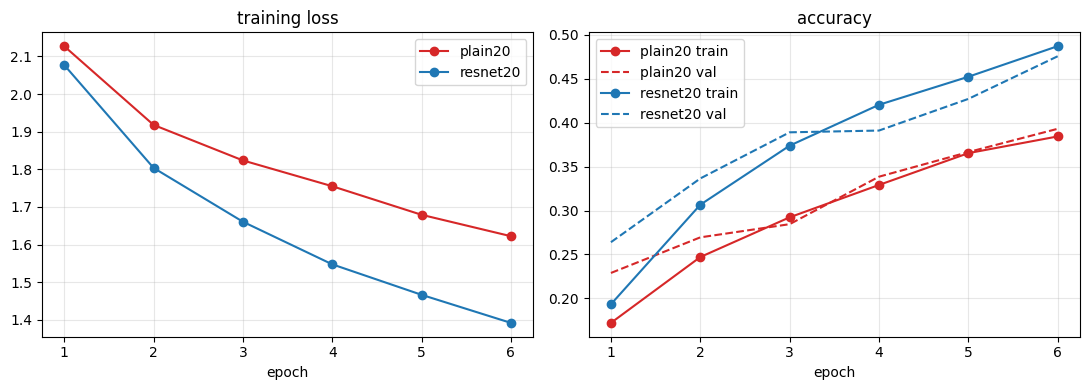

plain20   final train loss 1.622  train acc 0.384  val acc 0.393
resnet20  final train loss 1.392  train acc 0.487  val acc 0.475


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name, colour in (('plain20', 'tab:red'), ('resnet20', 'tab:blue')):
    hh = histories[name]
    ep = np.arange(1, len(hh['loss']) + 1)
    axes[0].plot(ep, hh['loss'], color=colour, marker='o', label=name)
    axes[1].plot(ep, hh['accuracy'], color=colour, marker='o', label=name + ' train')
    axes[1].plot(ep, hh['val_accuracy'], color=colour, ls='--', label=name + ' val')
axes[0].set_title('training loss'); axes[1].set_title('accuracy')
for ax in axes:
    ax.set_xlabel('epoch'); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

for name, hh in histories.items():
    print(f"{name:9s} final train loss {hh['loss'][-1]:.3f}  train acc {hh['accuracy'][-1]:.3f}"
          f"  val acc {hh['val_accuracy'][-1]:.3f}")

### Why we see this

The residual network is ahead on **training** loss from the first epoch. That is the point the ResNet
paper made: a deeper plain network is not worse because it overfits (overfitting would show a *low*
training loss and a high validation loss). It is worse because it is **harder to optimise**. The plain
network is not stuck for ever; give it many more epochs and it creeps up. But at equal budget, the skips
buy a network that learns faster, and the gap grows with depth: try Trial 1 below.

In our run: plain-20 reached about 38% training accuracy after 6 epochs, resnet-20 about 49%.
Validation followed the same order (about 39% and 48%). Both are far from finished; the comparison,
not the level, is the lesson.

---
# Part B - Transfer learning: borrow a trained backbone

---
## Step 13 - Take a backbone from `keras.applications`

`keras.applications` holds the famous architectures with an option to load weights trained on ImageNet
(1.2 million photos, 1,000 classes). We use **MobileNetV2** with width multiplier `alpha=0.35`: small
enough for a laptop CPU, and built from the depthwise separable blocks of Chapter 15. `include_top=False`
removes its 1,000-class head, so we get the feature extractor only.

**About the weights.** Pretrained weights are downloaded the first time you ask for them (a few MB here).
This lab runs with `weights=None` by default, so it works offline: the architecture is real but its
weights are random, so **Part B shows the mechanics, not the benefit**. The benefit, often tens of
percentage points on a small dataset, needs the pretrained weights. If you have internet access, change
the one marked line below to `'imagenet'` and run Part B again.

> **Predict:** MobileNetV2 has BatchNormalization layers. Before we freeze anything, will the summary
> report any *non-trainable* parameters?

In [13]:
WEIGHTS = None            # <<< CHANGE TO 'imagenet' FOR REAL TRANSFER LEARNING (needs a download)

IMG = 96                  # MobileNetV2 accepts 96, 128, 160, 192 or 224 for its ImageNet weights
base = keras.applications.MobileNetV2(input_shape=(IMG, IMG, 3), include_top=False,
                                      weights=WEIGHTS, alpha=0.35)
print("weights loaded :", WEIGHTS)
print("layers in base :", len(base.layers))
print("output shape   :", base.output.shape)

def counts(model):
    tr = sum(int(np.prod(w.shape)) for w in model.trainable_weights)
    nt = sum(int(np.prod(w.shape)) for w in model.non_trainable_weights)
    return tr, nt

tr, nt = counts(base)
print(f"trainable {tr:,}   non-trainable {nt:,}   total {base.count_params():,}")

weights loaded : None
layers in base : 154
output shape   : (None, 3, 3, 1280)
trainable 396,128   non-trainable 14,080   total 410,208


### Why we see this

Even with nothing frozen, there is a non-trainable share: the **moving mean and moving variance** of
every BatchNormalization layer (two of its four numbers per channel, Chapter 10). They are updated by
averaging, not by gradient descent, so Keras files them as non-trainable.

---
## Step 14 - Freeze the backbone

One line: `base.trainable = False`. Every weight in the base stops receiving updates.

> **Predict:** the new trainable count, and the new non-trainable count.

In [14]:
base.trainable = False
tr2, nt2 = counts(base)
print(f"after freezing: trainable {tr2:,}   non-trainable {nt2:,}")
assert tr2 == 0 and nt2 == tr + nt

after freezing: trainable 0   non-trainable 410,208


---
## Step 15 - Put a new head on it

The full model is: raw pixels -> resize to 96 x 96 -> **the backbone's own preprocessing** ->
frozen base -> global average pooling -> dropout -> `Dense(10)`.

Two details matter more than they look:

1. `preprocess_input` must be the one that belongs to *this* backbone. MobileNetV2 expects pixels
   scaled to [-1, 1] from raw 0-255 values, so we feed it raw pixels, **not** our /255 version.
2. We call `base(x, training=False)`. That keeps the BatchNormalization layers in inference mode
   (using their stored statistics) even later, when we unfreeze some layers for fine-tuning.

> **Predict:** the trainable parameter count of the head. The base outputs 1,280 channels; the head is
> `Dense(10)` on 1,280 numbers.

In [15]:
inputs = keras.Input(shape=(32, 32, 3))                 # raw CIFAR pixels, 0..255
x = layers.Resizing(IMG, IMG)(inputs)
x = keras.applications.mobilenet_v2.preprocess_input(x) # -> [-1, 1], as the base was trained
x = base(x, training=False)                             # BN stays in inference mode
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(10)(x)
tl_model = keras.Model(inputs, outputs, name='transfer')

tr3, nt3 = counts(tl_model)
print(f"whole model: trainable {tr3:,}   non-trainable {nt3:,}")
assert tr3 == 1280 * 10 + 10

whole model: trainable 12,810   non-trainable 410,208


---
## Step 16 - Phase 1: feature extraction (train the head only)

A small set on purpose: transfer learning shines when data is scarce. 2,000 training images, 1,000 for
validation, raw pixel values (the model does its own preprocessing).

> **Predict:** with `weights=None`, will the frozen random base give useful features? With `'imagenet'`?

In [16]:
xb_train, yb_train = x_all[:2_000].astype('float32'), y_all[:2_000]
xb_val, yb_val = x_all[40_000:41_000].astype('float32'), y_all[40_000:41_000]

tl_model.compile(optimizer=keras.optimizers.Adam(1e-3), loss=loss_fn, metrics=['accuracy'])
t = time.time()
h1 = tl_model.fit(xb_train, yb_train, epochs=3, batch_size=64,
                  validation_data=(xb_val, yb_val), verbose=0)
print(f"phase 1 ({time.time() - t:.0f}s)  val acc by epoch:",
      " ".join(f"{a:.3f}" for a in h1.history['val_accuracy']))

phase 1 (24s)  val acc by epoch: 0.100 0.107 0.107


---
## Step 17 - Phase 2: fine-tune the top of the backbone

Once the new head has settled, unfreeze the **last few layers** of the base and train on with a learning
rate about **100 times smaller**. Big updates at this point would wreck the pretrained features; small
ones adapt them to your data.

We leave every BatchNormalization layer frozen. Their stored statistics came from millions of
images; re-estimating them from batches of 64 CIFAR pictures would add noise, not knowledge.

**You must compile again** after changing `trainable`: the optimiser decides at compile time which
weights it updates.

> **Predict:** the trainable count after unfreezing the last 20 layers, roughly: thousands, or hundreds
> of thousands?

In [17]:
base.trainable = True
for layer in base.layers[:-20]:
    layer.trainable = False                          # keep the lower layers frozen
for layer in base.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False                      # keep BN statistics frozen

tr4, nt4 = counts(tl_model)
print(f"after partial unfreeze: trainable {tr4:,}   non-trainable {nt4:,}")

tl_model.compile(optimizer=keras.optimizers.Adam(1e-5), loss=loss_fn, metrics=['accuracy'])
t = time.time()
h2 = tl_model.fit(xb_train, yb_train, epochs=2, batch_size=64,
                  validation_data=(xb_val, yb_val), verbose=0)
print(f"phase 2 ({time.time() - t:.0f}s)  val acc by epoch:",
      " ".join(f"{a:.3f}" for a in h2.history['val_accuracy']))

after partial unfreeze: trainable 256,298   non-trainable 166,720


phase 2 (21s)  val acc by epoch: 0.107 0.107


### Why we see this

With `weights=None` the "pretrained" base is random, and validation accuracy stays low: a frozen random
network is a poor feature extractor, and two epochs of tiny fine-tuning steps cannot repair it. That is
not a failure of the recipe. It is the control experiment that shows where the value of transfer learning
lives: **in the weights, not in the architecture**.

Switch to `WEIGHTS = 'imagenet'` and run Part B again. The frozen base now turns each image into 1,280
numbers that already describe edges, textures and object parts, and a single `Dense(10)` trained for a
few epochs on 2,000 images typically does far better than Part A's networks trained from scratch on five
times as much data. Fine-tuning then adds a little more. (We do not quote a number: it depends on
your download and run, so measure it.)

---
## Trials: change one thing at a time

Write your prediction first. Run. Then fill in what you saw.

| # | Change | Predict | Observe |
|---|---|---|---|
| 1 | Step 9: `blocks_per_stage=5` (32 weight layers) for both networks | | |
| 2 | Step 9: `blocks_per_stage=1` (8 layers) for both | | |
| 3 | Step 10: measure the gradient on the *last* conv kernel (`grads[-4]`) instead of the first | | |
| 4 | Step 3: put the `Add` **after** the final ReLU instead of before it | | |
| 5 | Step 17: fine-tune with `Adam(1e-3)` instead of `1e-5` (with `'imagenet'` weights) | | |
| 6 | Step 15: replace `preprocess_input` with `x / 255.0` (with `'imagenet'` weights) | | |
| 7 | Step 17: unfreeze the whole base, including BatchNormalization | | |

Hints for checking yourself: in Trial 2 the gap should almost vanish (shallow plain networks train
fine); in Trial 1 it should widen; in Trials 5 and 6 accuracy usually drops, sometimes sharply.

---
## Exercises

1. Write a **pre-activation** residual block (BatchNorm -> ReLU -> Conv, twice, then add, with no ReLU
   after the addition). Count its parameters by hand before calling `count_params()`.
2. Replace the 1 x 1 projection in Step 6 with "zero padding" of the extra channels plus a stride-2
   slice of the skip (the ResNet paper's free option A). How many parameters does the block lose?
3. Turn Step 7's bottleneck into a stride-2 downsampling block. Where does the stride go, and what
   must the skip do?
4. Build a tiny **DenseNet** block: instead of `Add`, use `layers.Concatenate()`. What happens to the
   channel count after four such blocks with 16 new channels each, starting from 32?
5. In Part B, swap MobileNetV2 for `keras.applications.ResNet50(include_top=False)` with
   `weights=None`. Count its trainable and non-trainable parameters, and use the matching
   `keras.applications.resnet50.preprocess_input`.

---
## Cheat sheet

```python
# residual block (Functional API)
shortcut = x
y = layers.Conv2D(f, 3, strides=s, padding='same', activation='relu')(x)
y = layers.Conv2D(f, 3, padding='same')(y)
if s != 1 or x.shape[-1] != f:
    shortcut = layers.Conv2D(f, 1, strides=s)(x)     # projection: (C_in + 1) x f params
x = layers.ReLU()(layers.Add()([shortcut, y]))       # Add: 0 params

# transfer learning, two phases
base = keras.applications.MobileNetV2(include_top=False, weights='imagenet', input_shape=(96, 96, 3))
base.trainable = False                                # phase 1: freeze
x = keras.applications.mobilenet_v2.preprocess_input(inputs)
x = base(x, training=False)                           # BN in inference mode
... head ...; compile(Adam(1e-3)); fit
base.trainable = True                                 # phase 2: unfreeze the top only
for l in base.layers[:-20]: l.trainable = False
compile(Adam(1e-5)); fit                              # recompile, tiny learning rate
```

| Fact | Value |
|---|---|
| Parameters in `Add` | 0 |
| Residual block, 32 -> 32 channels, two 3 x 3 convs | 18,496 (same as plain) |
| Downsampling block 32 -> 64, stride 2, with 1 x 1 projection | 57,536 (projection 2,112) |
| Bottleneck 256 -> 64 -> 64 -> 256 vs two 3 x 3 at 256 | 70,016 vs 1,180,160 (16.9 x) |
| Fine-tuning learning rate | 10 to 100 times smaller than the head's |
| Must match the backbone | `preprocess_input`, input size, colour order |